# SNEAK conversation federation and model MMR evaluation

**Source-bound, partial project capture.** Two-model, two-question pilot only; no retrieval. V0 question-leaf scheme FAILED, corrected in V1 successor.

In [1]:
from pathlib import Path
import json,sys
root=Path.cwd()
sys.path.insert(0,str(root/'src'))
from sneak.fcg_registry import FCGRegistry, verify_rows
p0=root/'receipts/evaluations/SNEAK_20261020_CONVERSATION_FEDERATION.json'
p1=root/'receipts/evaluations/SNEAK_20261020_CONVERSATION_FEDERATION_V1_CORRECTED.json'
v0bytes=p0.read_bytes()
assert v0bytes.endswith(bytes([92,110]))
v0=json.loads(v0bytes[:-2]);v1=json.loads(p1.read_text())
print('v0 predecessor:',v0['successor']['mmr_root'])
print('v1 corrected:',v1['successor']['mmr_root'])
print('Federation:',v1['federation']['root'])

v0 predecessor: a24ecf8fcdde9ed0504bd2feb2f69cab811d4a18cc493ecd47bd187486aae9c2
v1 corrected: 2ff9f1a8d530278dc953bb14297d00314734e0d87a6b325995fbbdfb48c123e4
Federation: 8e1fe6ef6158b2e1381a9375030fcbc0dad4c1b334f7a128691ca3b8995417c7


## Prefix and inclusion verification

The MMR proves ledger integrity, not truth or complete conversation coverage.

In [2]:
rows=[json.loads(x) for x in (root/'data/fcg/sneak-016-replay.jsonl').read_text().splitlines() if x.strip()]
assert verify_rows(rows[:79])['mmr_root']==v0['parent']['mmr_root']
assert verify_rows(rows[:174])['mmr_root']==v1['parent']['mmr_root']
assert verify_rows(rows[:243])['mmr_root']==v1['successor']['mmr_root']
assert v1['federation']['inclusion_verified'] and v1['federation']['tamper_rejected']
print('Verified 243-leaf prefix; current full ledger:',FCGRegistry(root/'data/fcg/sneak-016-replay.jsonl').verify())

Verified 243-leaf prefix; current full ledger: {'verified': True, 'fco_count': 243, 'mmr_size': 480, 'mmr_root': '2ff9f1a8d530278dc953bb14297d00314734e0d87a6b325995fbbdfb48c123e4', 'fcg_edges': 255}


## Question inputs, models, outputs and deltas

Question identity uses SHA256(0x00 || exact UTF-8 question). Temporal delta is NOT_COMPUTED without repeated same-model observations.

In [3]:
for model,run in v1['model_roots'].items():
    print(model,'model root:',run['model_mmr']['root'])
    for q in run['questions']:
        print('   ',q['question_id'],'question root:',q['correct_question_leaf_sha256'],'MMR:',q['per_question_mmr']['root'],'delta_correct:',q['delta_correct_vs_baseline'],'delta_ms:',q['delta_ms_vs_baseline'])

hf.co/LiquidAI/LFM2.5-1.2B-Instruct-GGUF:latest model root: f7f8447e1ef527323e9a8d81d7c3a46f94a13a164b3fea481f3454d0a1fc0167
    01307e07 question root: 3ab8914d1dbf98b784bee1d0a1ad8d9f0a15c66e860ede5336428a8467744be5 MMR: 8e4c45e4e016a2b75e746f810a78990aa358e128375baca44b00946600790ae6 delta_correct: 0 delta_ms: -9949.01
    00aa905a question root: 512b465e5e2540044eaa103d11b2333d8c2a186d76cd79de79a0a15a2d786cdf MMR: e34d3b14f1e0e2c7eef513dd324ecfb0f3de3da01ab4f606bd3df7fed0f40dd5 delta_correct: 1 delta_ms: -501.39
qwen3:1.7b model root: 3024e313e64fee7ac364de00cf49ea0091a09bcb9de1ce33a0e2393bfe01db5d
    01307e07 question root: 3ab8914d1dbf98b784bee1d0a1ad8d9f0a15c66e860ede5336428a8467744be5 MMR: 03def6d2ef6e2f97704d0e352be9767dab438529711c6c8e422c8cff4f62296b delta_correct: 0 delta_ms: 0.0
    00aa905a question root: 512b465e5e2540044eaa103d11b2333d8c2a186d76cd79de79a0a15a2d786cdf MMR: 3558c51eeea3c49be79d1ec0ae16e4b2b18353e46020a2e566a2beeda760726a delta_correct: 0 delta_ms: 0.0


## Observed 2x2 correctness matrix

No inference on model superiority or memory gain is supported by this sample.

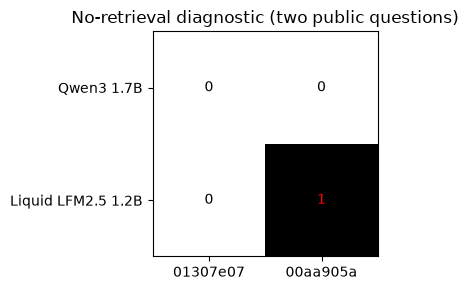

In [4]:
import matplotlib.pyplot as plt
pilot=json.loads((root/'receipts/evaluations/LMEV2_20261020_PILOT.json').read_text())
ids=[z['question_id'] for z in pilot['results'][0]['question_results']]
values=[[int(x['correct']) for x in item['question_results']] for item in pilot['results']]
fig,ax=plt.subplots(figsize=(7,3))
ax.imshow(values,vmin=0,vmax=1,cmap='Greys')
ax.set_xticks([0,1],ids)
ax.set_yticks([0,1],['Qwen3 1.7B','Liquid LFM2.5 1.2B'])
ax.set_title('No-retrieval diagnostic (two public questions)')
for i,row in enumerate(values):
    for j,v in enumerate(row):ax.text(j,i,str(v),ha='center',va='center',color=('red' if v else 'black'))
plt.tight_layout();plt.show()

## All requirements including optional

Both independent source inventories are captured. Their crosswalk and true acceptance remain uncomputed.

In [5]:
print('PDF requirements:',v1['official_source_classifications'])
assert v1['official_source_classifications']['OPTIONAL']==1
assert v1['official_source_classifications']['BONUS']==6
assert v1['requirement_source_occurrences_in_both_manifests']==115
assert v1['cross_manifest_identity_deduplication']=='NOT_COMPUTED'
assert not v1['all_conversations_captured']
print('Planner:',v1['live_band_planner'],'security:',v1['security_admission'],'coverage:',v1['coverage_state'])

PDF requirements: {'BONUS': 6, 'EVENT': 1, 'EXTRA_CREDIT': 3, 'JUDGING': 7, 'MANDATORY': 16, 'OPTIONAL': 1, 'PRIMER': 4, 'SETUP': 4, 'TRACK': 9, 'UNCONFIRMED': 5}
Planner: NOT_TESTED_AUTH_BLOCKED security: DENY coverage: PARTIAL


## Unresolved

Original full BAND message history, ChatGPT/Claude transcripts, the BAND planner identity, and cross-agent Cognee adoption have not been observed. A federation root cannot repair incomplete coverage.